# 7. Gene clusters and pathway flow

*Page 7 of 9.* [previous: 6. Pathways and therapy](https://robinson-vidva.github.io/mb-methylation-xai/06_pathways_and_therapy.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 8. Genes: names, cancer roles and literature](https://robinson-vidva.github.io/mb-methylation-xai/08_genes_roles_and_literature.html)

Pages 5 and 6 treat genes one at a time. This page asks how the concordant genes behave together,
and where the changed genes sit inside the pathways that define the subgroups. Four parts: clustering,
a network, pathway flow, and pathway activity per tumour.

## 1. Gene clusters

The concordant genes with both measurements were clustered by their promoter methylation across all
763 tumours (hierarchical clustering, average linkage, correlation distance, six clusters). The
expression panel uses the same gene order, so a block that is red (methylated) on the left should be
blue (silent) on the right if methylation controls expression.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from pathlib import Path
TAB = Path('../results/tables')
FIG = Path('../results/figures')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 90)

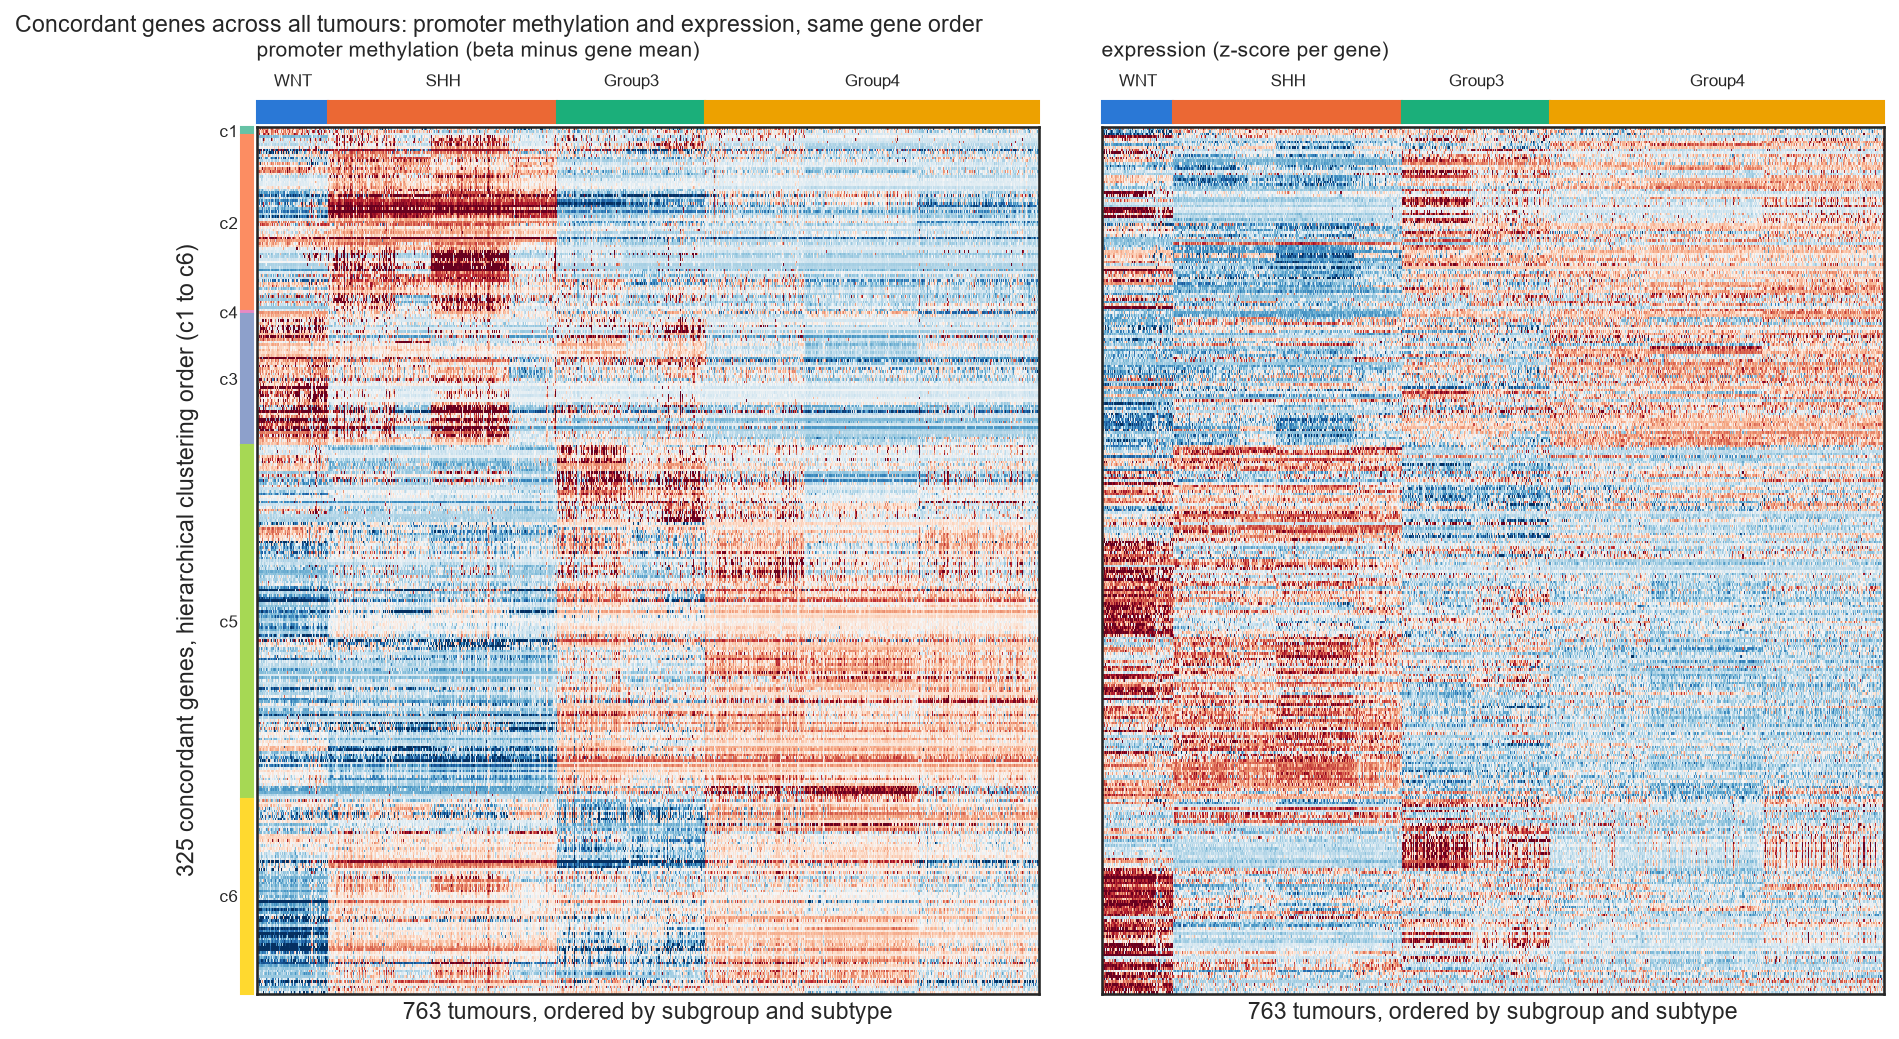

hypomethylated_in,WNT,SHH,Group3,Group4
cluster,,,,
1,0,2,0,1
2,11,0,14,41
3,0,3,0,46
4,0,0,0,1
5,44,86,0,3
6,45,0,28,0


In [2]:
display(Image(FIG / 'gene_clusters_heatmap.png'))
cl = pd.read_csv(TAB / 'gene_clusters.csv', index_col=0)
pd.crosstab(cl['cluster'], cl['hypomethylated_in'])[['WNT', 'SHH', 'Group3', 'Group4']]

In [3]:
enr = pd.read_csv(TAB / 'gene_cluster_enrichment.csv')
enr.groupby('query').head(6)[['query', 'source', 'name', 'p_value', 'intersection_size', 'term_size']]

,query,source,name,p_value,intersection_size,term_size
0,cluster 6,GO:BP,visual perception,1.373549e-12,17,191
1,cluster 6,GO:BP,sensory perception of light stimulus,1.640859e-12,17,193
2,cluster 6,GO:BP,detection of light stimulus,8.536553e-09,10,58
3,cluster 6,GO:BP,phototransduction,5.814788e-07,8,39
4,cluster 6,GO:BP,detection of external stimulus,1.378136e-05,10,119
5,cluster 6,KEGG,Phototransduction,1.480043e-05,5,27


The genes fall into subgroup blocks. One large cluster is hypomethylated in SHH and WNT tumours and
methylated in Group 3 and Group 4. Another is hypomethylated in Group 4, and a third in Group 3 and WNT.
The expression panel is the mirror image: where a block is unmethylated, the genes are expressed.
Methylation of these genes is organised by lineage, not gene by gene. Only one cluster returns
enriched terms, the Group 3 block, and the terms are visual perception and phototransduction: the
photoreceptor program again, now as a co-methylated block rather than a list.

## 2. Co-methylation network

A network makes the same point with less structure imposed. Nodes are concordant genes. An edge
joins two genes whose promoter methylation correlates across the 763 tumours with Spearman rho of
at least 0.6; red dashed edges mark anti-correlation of -0.6 or stronger. Communities were found by
greedy modularity. Node colour is the subgroup in which the gene is most hypomethylated; node size is
the number of edges. The five most connected genes per community are labelled.

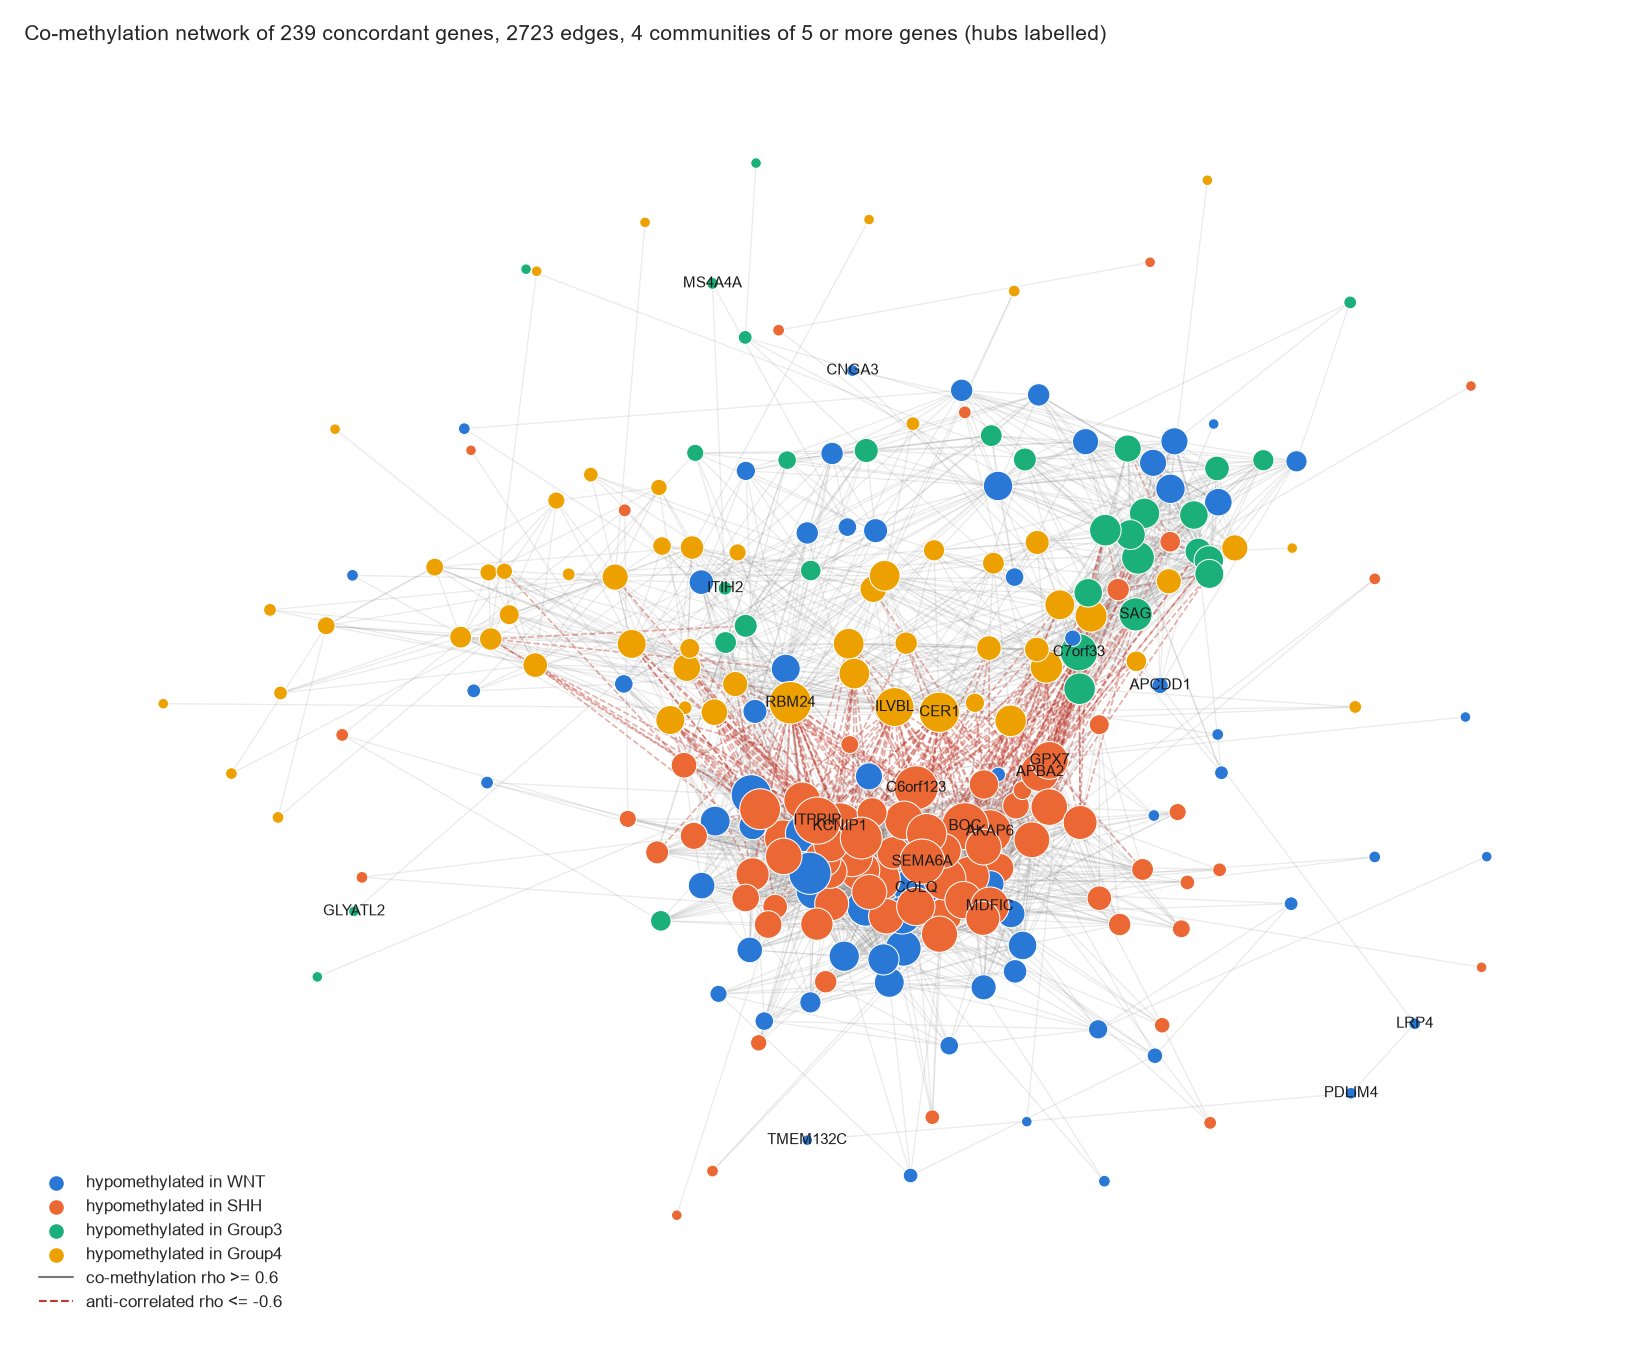

hypomethylated_in,WNT,SHH,Group3,Group4
community,,,,
1,43,54,9,0
2,7,5,20,58
3,14,21,0,0
4,5,0,0,0
5,0,0,3,0


In [4]:
display(Image(FIG / 'comethylation_network.png'))
net = pd.read_csv(TAB / 'network_communities.csv')
pd.crosstab(net['community'], net['hypomethylated_in'])[['WNT', 'SHH', 'Group3', 'Group4']]

In [5]:
pd.read_csv(TAB / 'network_hubs.csv')

,gene,community,degree,concordant_in,hypomethylated_in,cluster_A
0,ITPRIP,1,82,Group4,SHH,5
1,KCNIP1,1,81,WNT,SHH,5
2,COLQ,1,76,WNT,WNT,5
3,SEMA6A,1,75,SHH,SHH,5
4,C6orf123,1,71,SHH,SHH,5
5,RBM24,2,66,SHH,Group4,2
6,CER1,2,59,WNT,Group4,2
7,ILVBL,2,55,SHH,Group4,2
8,C7orf33,2,50,SHH,Group3,2
9,SAG,2,39,SHH,Group3,2


Three large communities appear: two dominated by SHH genes and one by Group 3 and Group 4 genes.
The anti-correlated edges run between the SHH community and the Group 3 and Group 4 community: the
same gene is unmethylated in one lineage and methylated in the other. Hubs such as BOC (a Hedgehog
co-receptor), SEMA6A and KCNIP1 on the SHH side, and RBM24, CER1 and SAG on the Group 3 and 4 side,
are the genes whose methylation best summarises each block. These are candidate marker CpGs.

## 3. Pathway flow

A pathway is a chain: ligand, receptor, transducer, transcription factor, target genes. Where in the
chain a subgroup changes tells how the pathway is switched on. Three pathways were examined: Hedgehog
(the SHH subgroup), Wnt (the WNT subgroup), and the photoreceptor program (Group 3). Membership comes
from KEGG through its public API. The table counts, per pathway and subgroup, members with increased
or decreased expression, promoter changes, and concordant genes.

In [6]:
ms = pd.read_csv(TAB / 'pathway_membership_summary.csv')
ms.set_index(['pathway', 'members', 'with_both_measurements', 'group'])

kegg  expression_up  expression_down  promoter_hypomethylated  promoter_hypermethylated  \
pathway           members with_both_measurements group                                                                                                 
Hedgehog          56      51                     WNT     hsa04340              4                2                        0                         2   
                                                 SHH     hsa04340             11                1                        2                         1   
                                                 Group3  hsa04340              1                5                        0                         1   
                                                 Group4  hsa04340              0                7                        1                         2   
Wnt               178     164                    WNT     hsa04310             34                7                       11                         6   
                                                 SHH     hsa04310             19                9                        5                         9   
                                                 Group3  hsa04310              5                8                        6                         4   
                                                 Group4  hsa04310              6               18                        4                         8   
Phototransduction 29      26                     WNT     hsa04744              0                0                        4                         4   
                                                 SHH     hsa04744              1                5                        1                         3   
                                                 Group3  hsa04744             12                0                        8                         0   
                                                 Group4  hsa04744              0                0                        2                         3   

                                                         concordant  
pathway           members with_both_measurements group               
Hedgehog          56      51                     WNT              0  
                                                 SHH              2  
                                                 Group3           1  
                                                 Group4           1  
Wnt               178     164                    WNT              8  
                                                 SHH              4  
                                                 Group3           0  
                                                 Group4           2  
Phototransduction 29      26                     WNT              0  
                                                 SHH              1  
                                                 Group3           7  
                                                 Group4           0

The figure places a curated core of each pathway in signalling order. Left block: change in promoter
beta per subgroup; right block: change in log2 expression. Numbers appear where the change passes
FDR 0.05 and the threshold used on page 5; a box marks a concordant gene.

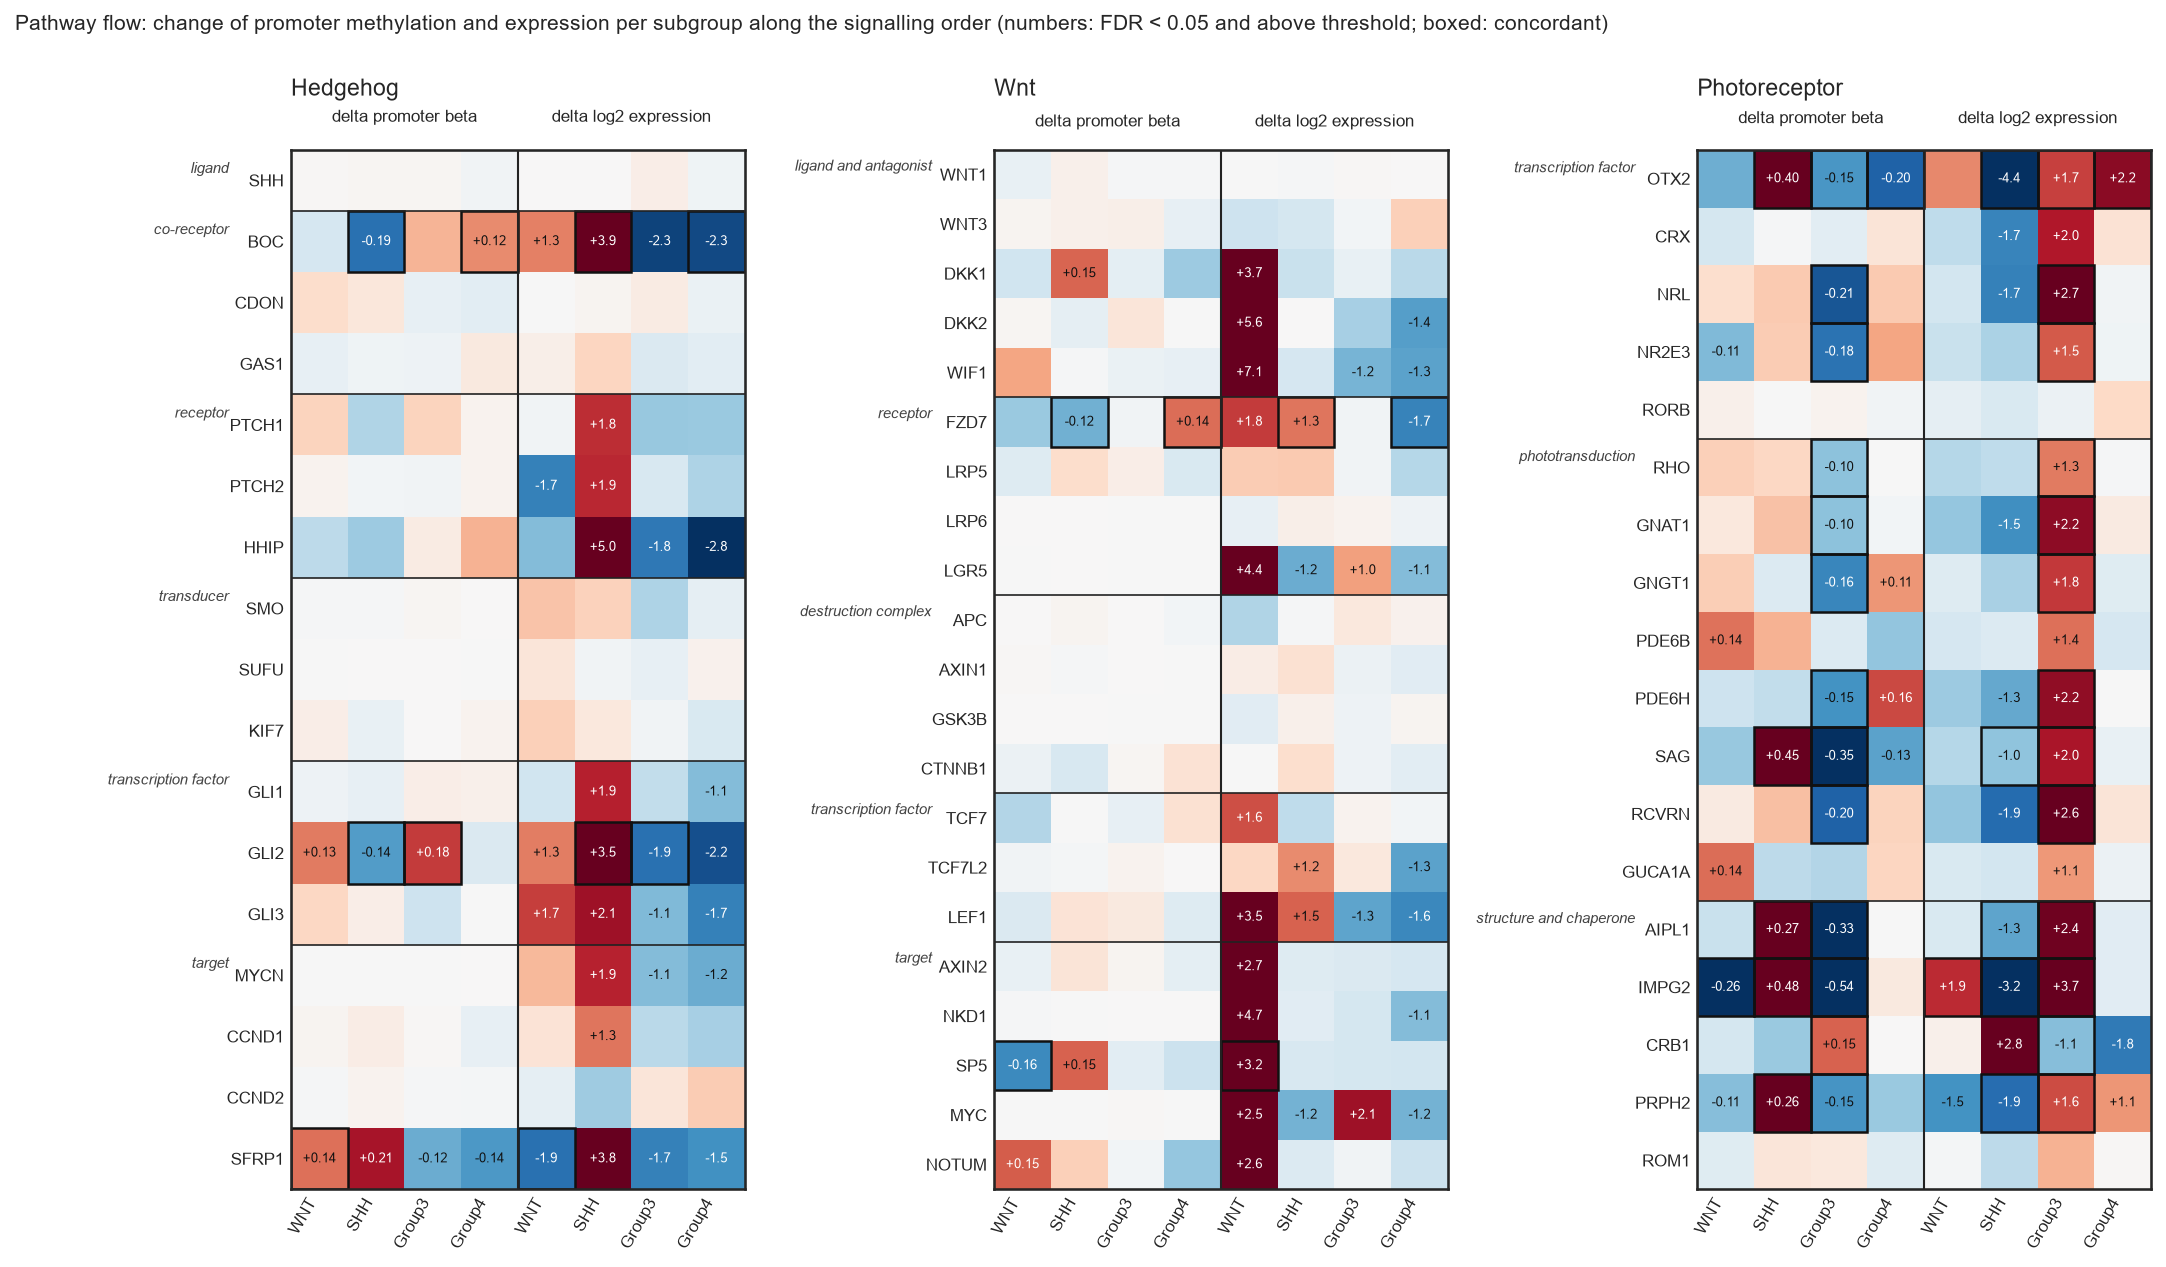

In [7]:
display(Image(FIG / 'pathway_flow.png'))

In [8]:
flow = pd.read_csv(TAB / 'pathway_flow.csv')
flow[flow['concordant']][['pathway', 'stage', 'gene', 'group', 'delta_promoter_beta', 'delta_log2_expression']].reset_index(drop=True)

,pathway,stage,gene,group,delta_promoter_beta,delta_log2_expression
0,Hedgehog,co-receptor,BOC,SHH,-0.1859,3.8632
1,Hedgehog,co-receptor,BOC,Group4,0.1182,-2.2506
2,Hedgehog,transcription factor,GLI2,SHH,-0.1394,3.4677
3,Hedgehog,transcription factor,GLI2,Group3,0.1750,-1.8600
4,Hedgehog,target,SFRP1,WNT,0.1375,-1.8665
5,Wnt,receptor,FZD7,SHH,-0.1199,1.3362
6,Wnt,receptor,FZD7,Group4,0.1388,-1.6702
7,Wnt,target,SP5,WNT,-0.1601,3.1666
8,Photoreceptor,transcription factor,OTX2,SHH,0.3968,-4.4023
9,Photoreceptor,transcription factor,OTX2,Group3,-0.1455,1.7065


**Hedgehog in SHH tumours.** The output of the pathway is on: PTCH1, PTCH2, HHIP, GLI1, GLI2, MYCN,
CCND1 and SFRP1 are all over-expressed. Almost none of their promoters change; only BOC and GLI2 are
concordant. The ligand SHH, the transducers SMO, SUFU and KIF7 show nothing at either level. This is
the signature of a pathway switched on by mutation (PTCH1, SMO or SUFU loss, upstream of the targets):
the signal appears as target gene output, and methylation is silent.

**Wnt in WNT tumours.** The same pattern. AXIN2, LEF1, NKD1, DKK1, DKK2, WIF1, SP5, NOTUM and MYC are
strongly over-expressed, the classic beta-catenin target set, while the promoters of CTNNB1, APC and
the destruction complex do not move. CTNNB1 mutation drives the subgroup, and the targets respond at
the expression level. Only SP5 is concordant.

**Photoreceptor program in Group 3.** Here the chain changes at every level and in both measurements.
The transcription factors OTX2, NRL and NR2E3 are hypomethylated and expressed; the phototransduction
genes RHO, GNAT1, GNGT1, PDE6H, SAG and RCVRN follow; the structural genes AIPL1, IMPG2 and PRPH2
follow too. Seven of the 26 measured members are concordant in Group 3. The mirror image holds in SHH
tumours, where OTX2, SAG, AIPL1, IMPG2 and PRPH2 are hypermethylated and silent. This is a program
controlled by promoter methylation, not by a mutation.

## 4. Pathway activity per tumour

The same contrast, reduced to one number per tumour: the mean expression of each pathway's target
genes, and the mean promoter methylation of the same genes.

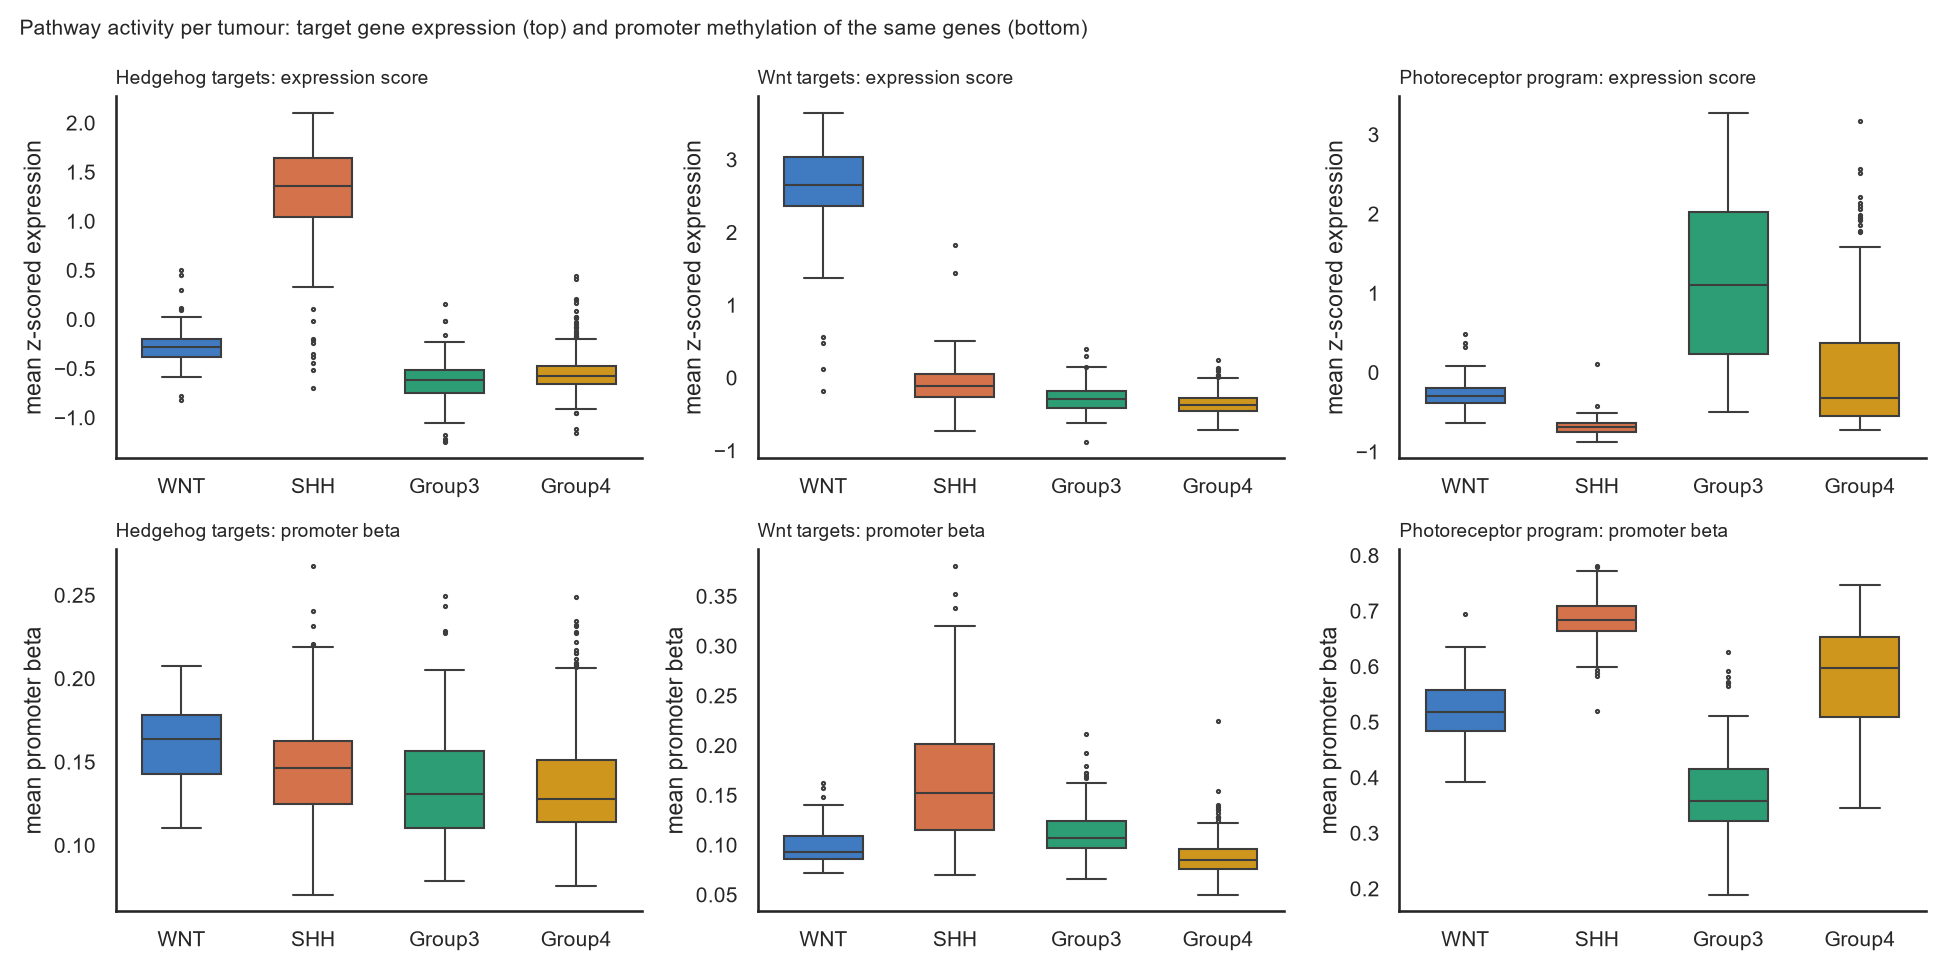

group,Group3,Group4,SHH,WNT
Hedgehog targets | expression score,-0.613,-0.572,1.361,-0.281
Hedgehog targets | promoter beta,0.131,0.128,0.146,0.164
Wnt targets | expression score,-0.290,-0.375,-0.111,2.649
Wnt targets | promoter beta,0.108,0.085,0.153,0.093
Photoreceptor program | expression score,1.103,-0.327,-0.688,-0.296
Photoreceptor program | promoter beta,0.357,0.598,0.684,0.518


In [9]:
display(Image(FIG / 'pathway_activity.png'))
act = pd.read_csv(TAB / 'pathway_activity_scores.csv', index_col=0)
act.groupby('group')[[c for c in act.columns if '|' in c]].median().round(3).T

Hedgehog and Wnt target expression is specific to SHH and WNT tumours, and the promoter methylation
of those targets is flat across subgroups. The photoreceptor program is high in Group 3 and its
promoters are clearly less methylated there than in every other subgroup.

**What this means for therapy.** A pathway switched on by mutation is targeted at the mutated node.
That is why SMO inhibitors work in SHH tumours and why the methylation state of Hedgehog targets adds
nothing to that decision. A program switched on by demethylation is a different kind of target. Its
promoter methylation is a per-tumour readout that could serve as a biomarker, and the program itself,
here the NRL and CRX photoreceptor identity of Group 3, is a dependency that has been proposed as a
therapeutic entry point. Which Group 3 tumours carry the program, and how strongly, is visible in the
top right panel. This is as far as array data can go; it does not test any drug.

*Page 7 of 9.* [previous: 6. Pathways and therapy](https://robinson-vidva.github.io/mb-methylation-xai/06_pathways_and_therapy.html) | [index](https://robinson-vidva.github.io/mb-methylation-xai/) | [next: 8. Genes: names, cancer roles and literature](https://robinson-vidva.github.io/mb-methylation-xai/08_genes_roles_and_literature.html)